# Numerical Linear Algebra — Theory Notebook

> *"It is a capital mistake to theorize before one has data — and in numerical LA, the data is the condition number."*

Interactive derivations covering: LU with pivoting, QR factorization, condition numbers, conjugate gradient, iterative methods, and eigenvalue algorithms.

**Companion:** [notes.md](notes.md) | [exercises.ipynb](exercises.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import scipy.linalg as sla
import numpy.linalg as nla

try:
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    try:
        import seaborn as sns
        sns.set_theme(style='whitegrid', palette='colorblind')
        HAS_SNS = True
    except ImportError:
        plt.style.use('seaborn-v0_8-whitegrid')
        HAS_SNS = False
    mpl.rcParams.update({
        'figure.figsize': (10, 6), 'figure.dpi': 120,
        'font.size': 13, 'axes.titlesize': 15, 'axes.labelsize': 13,
        'legend.fontsize': 11, 'lines.linewidth': 2.0,
        'axes.spines.top': False, 'axes.spines.right': False,
    })
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

COLORS = {
    'primary':   '#0077BB',
    'secondary': '#EE7733',
    'tertiary':  '#009988',
    'error':     '#CC3311',
    'neutral':   '#555555',
    'highlight': '#EE3377',
}

np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)
print('Setup complete.')

print("Chapter helper setup complete.")

Setup complete.
Chapter helper setup complete.


---

## 1. LU Factorization with Partial Pivoting

Implement GEPP from scratch and verify backward stability.

In [3]:
# === 1.1 GEPP Implementation ===

def lu_pivot(A):
    """Gaussian elimination with partial pivoting. Returns P, L, U."""
    n = A.shape[0]
    A = A.astype(np.float64).copy()
    P = np.eye(n)
    L = np.zeros((n, n))

    for k in range(n - 1):
        pivot_row = k + np.argmax(np.abs(A[k:, k]))
        if pivot_row != k:
            A[[k, pivot_row], :]  = A[[pivot_row, k], :]
            P[[k, pivot_row], :]  = P[[pivot_row, k], :]
            L[[k, pivot_row], :k] = L[[pivot_row, k], :k]
        for i in range(k + 1, n):
            L[i, k] = A[i, k] / A[k, k]
            A[i, k:] -= L[i, k] * A[k, k:]

    L += np.eye(n)
    U = np.triu(A)
    return P, L, U

# Test on random 5x5
np.random.seed(42)
A = np.random.randn(5, 5)
P, L, U = lu_pivot(A)

print('P @ A - L @ U (residual):')
residual = P @ A - L @ U
print(residual)
print(f'Max entry: {np.abs(residual).max():.2e}')

ok = np.allclose(P @ A, L @ U, atol=1e-12)
print(f"{'PASS' if ok else 'FAIL'} - PA = LU verified")

# Verify L has unit diagonal and |L_ij| <= 1
ok_L = np.allclose(np.diag(L), 1.0) and np.all(np.abs(L) <= 1.0 + 1e-10)
print(f"{'PASS' if ok_L else 'FAIL'} - L has unit diagonal and |L_ij| <= 1")

P @ A - L @ U (residual):
[[ 0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0. -0.  0.  0.]
 [-0.  0. -0. -0.  0.]]
Max entry: 4.44e-16
PASS - PA = LU verified
PASS - L has unit diagonal and |L_ij| <= 1


In [4]:
# === 1.2 Triangular Solves ===

def forward_sub(L, b):
    """Solve Lx = b, L lower triangular with unit diagonal."""
    n = len(b)
    x = np.zeros(n)
    for i in range(n):
        x[i] = b[i] - L[i, :i] @ x[:i]
    return x

def back_sub(U, b):
    """Solve Ux = b, U upper triangular."""
    n = len(b)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - U[i, i+1:] @ x[i+1:]) / U[i, i]
    return x

def solve_lu(A, b):
    P, L, U = lu_pivot(A)
    return back_sub(U, forward_sub(L, P @ b))

# Verify against numpy
b = np.random.randn(5)
x_lu = solve_lu(A, b)
x_np = nla.solve(A, b)

print('Custom solve vs numpy.linalg.solve:')
print(f'Max difference: {np.abs(x_lu - x_np).max():.2e}')
print(f'Residual ||Ax - b||: {nla.norm(A @ x_lu - b):.2e}')

ok = np.allclose(x_lu, x_np, atol=1e-10)
print(f"{'PASS' if ok else 'FAIL'} - custom LU matches numpy")

Custom solve vs numpy.linalg.solve:
Max difference: 2.22e-15
Residual ||Ax - b||: 7.29e-16
PASS - custom LU matches numpy


---

## 2. Demonstrating Instability Without Pivoting

A near-zero pivot causes catastrophic growth in the elimination process.

In [5]:
# === 2.1 Near-Zero Pivot Disaster ===

def lu_no_pivot(A):
    """LU without pivoting — UNSTABLE."""
    n = A.shape[0]
    A = A.astype(np.float64).copy()
    L = np.eye(n)
    for k in range(n - 1):
        if abs(A[k, k]) < 1e-15:
            raise ValueError(f'Near-zero pivot at step {k}: {A[k,k]}')
        for i in range(k + 1, n):
            L[i, k] = A[i, k] / A[k, k]
            A[i, k:] -= L[i, k] * A[k, k:]
    return L, np.triu(A)

# Matrix with tiny (1,1) entry — pivot is eps
eps_vals = [1e-3, 1e-6, 1e-10, 1e-14]

print('Effect of small pivot on solution accuracy:')
print(f'{"eps":>10}  {"No-pivot err":>15}  {"GEPP err":>15}')

b = np.array([1.0, 2.0])
for eps in eps_vals:
    A = np.array([[eps, 1.0], [1.0, 1.0]])
    x_true = nla.solve(A, b)

    # No-pivot solution
    try:
        L_np, U_np = lu_no_pivot(A)
        x_np = back_sub(U_np, forward_sub(L_np, b))
        err_np = nla.norm(x_np - x_true) / nla.norm(x_true)
    except ValueError:
        err_np = float('nan')

    # GEPP solution
    x_gepp = solve_lu(A, b)
    err_gepp = nla.norm(x_gepp - x_true) / nla.norm(x_true)

    print(f'{eps:10.0e}  {err_np:15.3e}  {err_gepp:15.3e}')

Effect of small pivot on solution accuracy:
       eps     No-pivot err         GEPP err
     1e-03        1.601e-14        0.000e+00
     1e-06        3.984e-12        0.000e+00
     1e-10        5.844e-08        0.000e+00
     1e-14        5.652e-04        0.000e+00


---

## 3. Normal Equations vs QR: Condition Number Squaring

Demonstrate that $\kappa(A^\top A) = \kappa(A)^2$ and its effect on accuracy.

In [6]:
# === 3.1 Condition Number Squaring ===

def build_matrix_with_kappa(kappa, m=50, n=10):
    """Build m x n matrix with given condition number."""
    # Generate orthogonal matrices
    U, _ = nla.qr(np.random.randn(m, n))
    Vt, _ = nla.qr(np.random.randn(n, n))
    # Singular values from 1 to kappa
    sigma = np.logspace(0, np.log10(kappa), n)
    return U @ np.diag(sigma) @ Vt, sigma

np.random.seed(42)
kappas = [10, 100, 1e4, 1e6, 1e8]

print(f'{"kappa(A)":>12}  {"kappa(AtA)":>14}  {"ratio":>10}')
for kappa in kappas:
    A, _ = build_matrix_with_kappa(kappa)
    k_A = nla.cond(A)
    k_AtA = nla.cond(A.T @ A)
    print(f'{k_A:12.3e}  {k_AtA:14.3e}  {k_AtA/k_A**2:10.3f}')

print()
print('kappa(A^T A) ≈ kappa(A)^2 — confirmed')

    kappa(A)      kappa(AtA)       ratio
   1.000e+01       1.000e+02       1.000
   1.000e+02       1.000e+04       1.000
   1.000e+04       1.000e+08       1.000
   1.000e+06       1.000e+12       1.000
   1.000e+08       9.470e+15       0.947

kappa(A^T A) ≈ kappa(A)^2 — confirmed


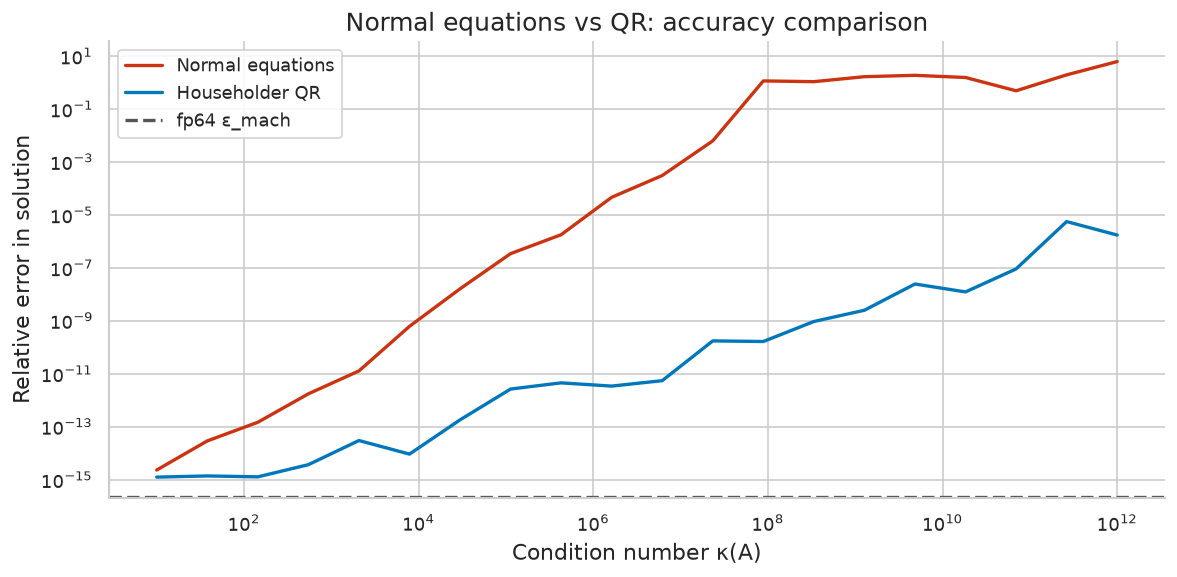

Plot displayed.


In [7]:
# === 3.2 Accuracy Comparison ===

np.random.seed(42)
kappas_test = np.logspace(1, 12, 20)
err_normal = []
err_qr = []

for kappa in kappas_test:
    A, sigma = build_matrix_with_kappa(kappa, m=50, n=10)
    x_true = np.random.randn(10)
    b = A @ x_true

    # Normal equations
    try:
        x_n = nla.solve(A.T @ A, A.T @ b)
        err_n = nla.norm(x_n - x_true) / nla.norm(x_true)
    except:
        err_n = 1.0

    # QR (lstsq)
    x_q, _, _, _ = nla.lstsq(A, b, rcond=None)
    err_q = nla.norm(x_q - x_true) / nla.norm(x_true)

    err_normal.append(err_n)
    err_qr.append(err_q)

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.loglog(kappas_test, err_normal, color=COLORS['error'], label='Normal equations')
    ax.loglog(kappas_test, err_qr,     color=COLORS['primary'], label='Householder QR')
    ax.axhline(np.finfo(np.float64).eps, color=COLORS['neutral'],
               linestyle='--', label='fp64 ε_mach')
    ax.set_xlabel('Condition number κ(A)')
    ax.set_ylabel('Relative error in solution')
    ax.set_title('Normal equations vs QR: accuracy comparison')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print('Plot displayed.')

---

## 4. Condition Number and Digit Loss

Verify: if $\kappa(A) = 10^k$, then $k$ digits are lost in solving $Ax = b$.

In [8]:
# === 4.1 Digits Lost as a Function of kappa ===

np.random.seed(0)
n = 10
kappas = [1e1, 1e3, 1e5, 1e7, 1e9, 1e11, 1e13]

print(f'{"kappa(A)":>12}  {"log10(kappa)":>14}  {"rel error":>12}  {"digits lost":>12}')
eps64 = np.finfo(np.float64).eps

for kappa in kappas:
    A, _ = build_matrix_with_kappa(kappa, m=n, n=n)
    x_true = np.random.randn(n)
    b = A @ x_true
    x_comp = nla.solve(A, b)
    rel_err = nla.norm(x_comp - x_true) / nla.norm(x_true)
    digits_lost = max(0, np.log10(max(rel_err, 1e-16)))
    print(f'{kappa:12.1e}  {np.log10(kappa):14.1f}  {rel_err:12.3e}  {digits_lost:12.1f}')

print()
print(f'fp64 has ~15 significant digits. At kappa=1e15, all accuracy is lost.')

    kappa(A)    log10(kappa)     rel error   digits lost
     1.0e+01             1.0     3.540e-16           0.0
     1.0e+03             3.0     8.770e-15           0.0
     1.0e+05             5.0     9.497e-13           0.0
     1.0e+07             7.0     7.655e-11           0.0
     1.0e+09             9.0     3.639e-09           0.0
     1.0e+11            11.0     1.139e-07           0.0
     1.0e+13            13.0     5.929e-05           0.0

fp64 has ~15 significant digits. At kappa=1e15, all accuracy is lost.


---

## 5. Householder QR Factorization

Implement QR via Householder reflectors and verify orthogonality.

In [9]:
# === 5.1 Householder Reflector ===

def householder_vector(x):
    """Compute v such that H = I - 2vv^T/v^Tv zeros out x[1:]."""
    x = x.copy().astype(np.float64)
    n = len(x)
    sign = 1.0 if x[0] >= 0 else -1.0
    v = x.copy()
    v[0] += sign * nla.norm(x)
    v = v / nla.norm(v)
    return v

def householder_qr(A):
    """QR factorization via Householder reflectors."""
    m, n = A.shape
    A = A.copy().astype(np.float64)
    Q = np.eye(m)

    for k in range(min(m-1, n)):
        v = householder_vector(A[k:, k])
        # Apply H_k to A[k:, k:]: A -= 2v(v^T A)
        A[k:, k:] -= 2 * np.outer(v, v @ A[k:, k:])
        # Accumulate Q: Q[k:, :] -= 2v(v^T Q[k:, :])
        Q[k:, :] -= 2 * np.outer(v, v @ Q[k:, :])

    return Q.T, np.triu(A)

# Test
np.random.seed(42)
m, n = 8, 5
A = np.random.randn(m, n)
Q, R = householder_qr(A)

print('Householder QR verification:')
print(f'||Q^T Q - I||_F = {nla.norm(Q.T @ Q - np.eye(m)):.2e}')
print(f'||QR - A||_F   = {nla.norm(Q @ R - A):.2e}')
print(f'R lower triangle zeros: {np.allclose(np.tril(R, -1), 0)}')

ok = np.allclose(Q.T @ Q, np.eye(m)) and np.allclose(Q @ R, A)
print(f"{'PASS' if ok else 'FAIL'} - Householder QR verified")

Householder QR verification:
||Q^T Q - I||_F = 1.27e-15
||QR - A||_F   = 2.24e-15
R lower triangle zeros: True
PASS - Householder QR verified


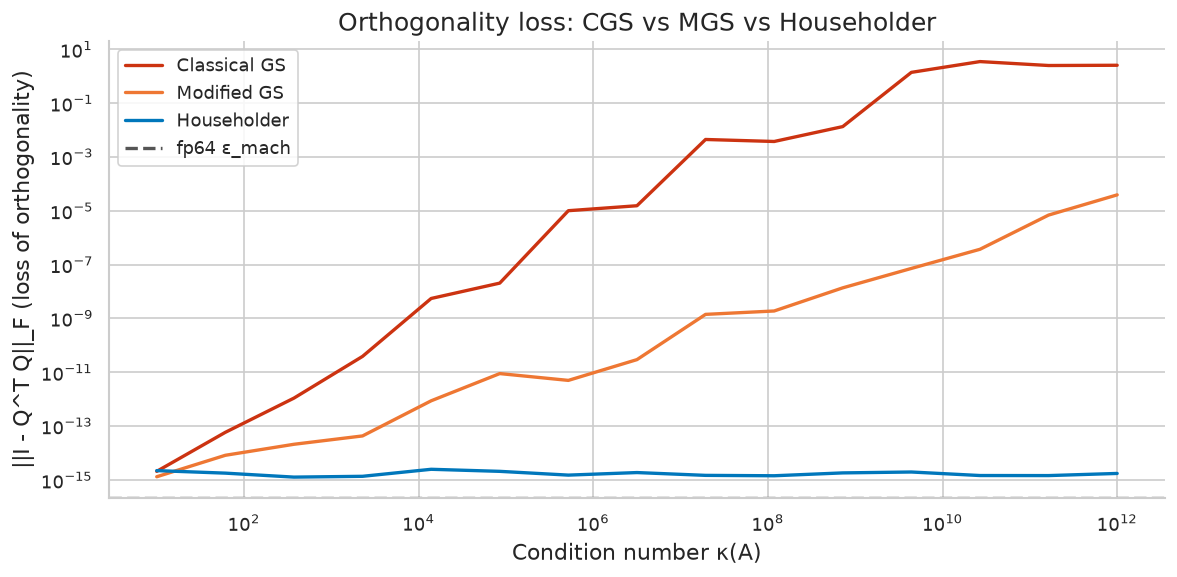

Plot displayed.


In [10]:
# === 5.2 Loss of Orthogonality: CGS vs MGS vs Householder ===

def cgs_qr(A):
    """Classical Gram-Schmidt QR."""
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for k in range(n):
        q = A[:, k].copy()
        for i in range(k):
            R[i, k] = Q[:, i] @ A[:, k]
            q -= R[i, k] * Q[:, i]
        R[k, k] = nla.norm(q)
        Q[:, k] = q / R[k, k]
    return Q, R

def mgs_qr(A):
    """Modified Gram-Schmidt QR."""
    m, n = A.shape
    Q = A.copy().astype(np.float64)
    R = np.zeros((n, n))
    for k in range(n):
        R[k, k] = nla.norm(Q[:, k])
        Q[:, k] /= R[k, k]
        for j in range(k+1, n):
            R[k, j] = Q[:, k] @ Q[:, j]
            Q[:, j] -= R[k, j] * Q[:, k]
    return Q, R

# Test on ill-conditioned matrix
np.random.seed(42)
kappas_test = np.logspace(1, 12, 15)
orth_loss_cgs = []
orth_loss_mgs = []
orth_loss_hh  = []

for kappa in kappas_test:
    A, _ = build_matrix_with_kappa(kappa, m=30, n=10)
    Q_cgs, _ = cgs_qr(A)
    Q_mgs, _ = mgs_qr(A)
    Q_hh,  _ = householder_qr(A)
    orth_loss_cgs.append(nla.norm(Q_cgs.T @ Q_cgs - np.eye(10)))
    orth_loss_mgs.append(nla.norm(Q_mgs.T @ Q_mgs - np.eye(10)))
    orth_loss_hh.append(nla.norm(Q_hh[:, :10].T @ Q_hh[:, :10] - np.eye(10)))

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.loglog(kappas_test, orth_loss_cgs, color=COLORS['error'], label='Classical GS')
    ax.loglog(kappas_test, orth_loss_mgs, color=COLORS['secondary'], label='Modified GS')
    ax.loglog(kappas_test, orth_loss_hh,  color=COLORS['primary'], label='Householder')
    ax.axhline(np.finfo(np.float64).eps, color=COLORS['neutral'],
               linestyle='--', label='fp64 ε_mach')
    ax.set_xlabel('Condition number κ(A)')
    ax.set_ylabel('||I - Q^T Q||_F (loss of orthogonality)')
    ax.set_title('Orthogonality loss: CGS vs MGS vs Householder')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print('Plot displayed.')

---

## 6. Conjugate Gradient Method

Implement CG and verify the convergence rate $\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^k$.

In [11]:
# === 6.1 CG Implementation ===

def conjugate_gradient(A, b, x0=None, tol=1e-12, max_iter=None):
    """Conjugate gradient for SPD system Ax = b."""
    n = len(b)
    if x0 is None: x0 = np.zeros(n)
    if max_iter is None: max_iter = 2 * n

    x = x0.copy().astype(np.float64)
    r = b - A @ x
    p = r.copy()
    rs_old = r @ r
    residuals = [np.sqrt(rs_old) / nla.norm(b)]

    for k in range(max_iter):
        Ap = A @ p
        alpha = rs_old / (p @ Ap)
        x += alpha * p
        r -= alpha * Ap
        rs_new = r @ r
        residuals.append(np.sqrt(rs_new) / nla.norm(b))
        if residuals[-1] < tol:
            break
        beta = rs_new / rs_old
        p = r + beta * p
        rs_old = rs_new

    return x, residuals

# Test on small SPD system
np.random.seed(42)
n = 20
B = np.random.randn(n, n)
A_spd = B.T @ B + 0.1 * np.eye(n)  # Make SPD
b_vec = np.random.randn(n)
x_true = nla.solve(A_spd, b_vec)

x_cg, residuals = conjugate_gradient(A_spd, b_vec)
print(f'CG converged in {len(residuals)-1} iterations')
print(f'Final residual: {residuals[-1]:.2e}')
print(f'Forward error: {nla.norm(x_cg - x_true) / nla.norm(x_true):.2e}')

ok = nla.norm(x_cg - x_true) / nla.norm(x_true) < 1e-10
print(f"{'PASS' if ok else 'FAIL'} - CG converged to correct solution")

CG converged in 24 iterations
Final residual: 9.84e-13
Forward error: 2.07e-14
PASS - CG converged to correct solution


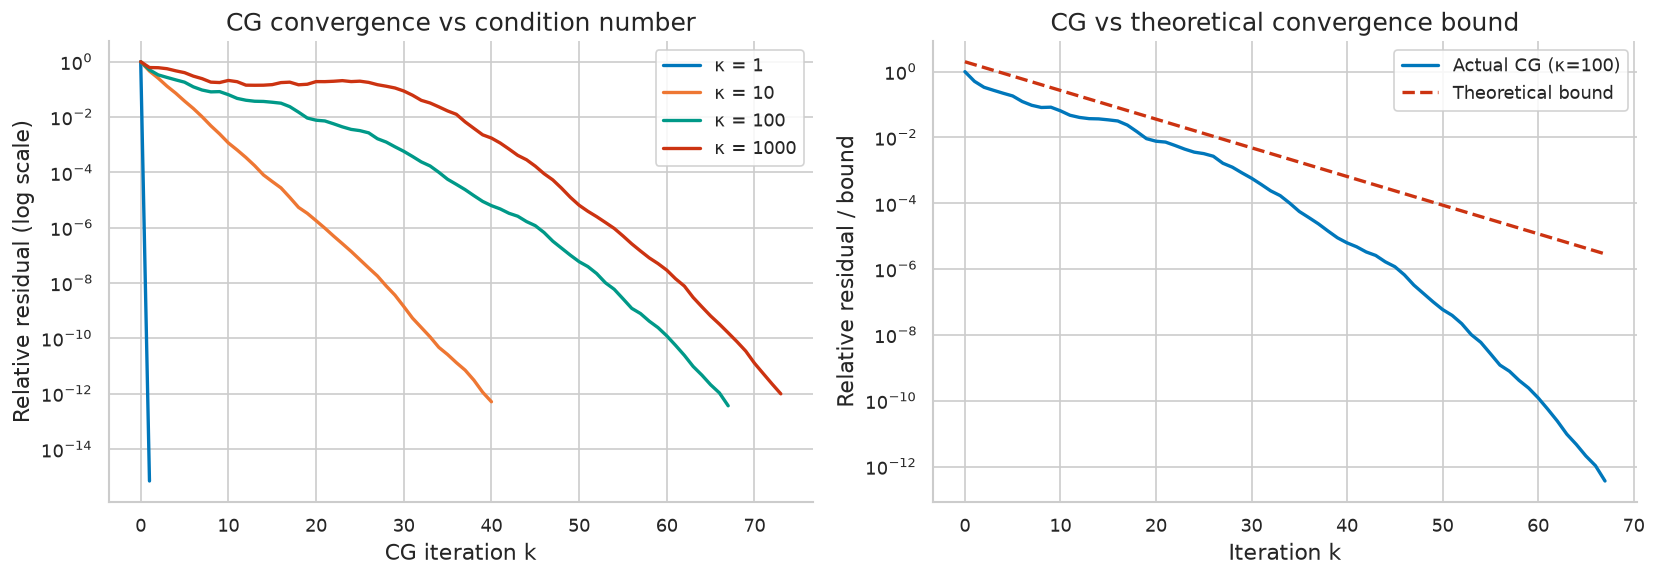

Plot displayed.


In [12]:
# === 6.2 CG Convergence vs Condition Number ===

np.random.seed(42)
n = 100

kappa_vals = [1, 10, 100, 1000]
convergence_data = {}

for kappa in kappa_vals:
    # Build SPD matrix with condition number kappa
    lam = np.linspace(1, kappa, n)
    Q, _ = nla.qr(np.random.randn(n, n))
    A_k = Q @ np.diag(lam) @ Q.T
    b_k = np.random.randn(n)

    _, residuals = conjugate_gradient(A_k, b_k, max_iter=200)
    convergence_data[kappa] = residuals

if HAS_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    color_list = [COLORS['primary'], COLORS['secondary'],
                  COLORS['tertiary'], COLORS['error']]
    for (kappa, res), col in zip(convergence_data.items(), color_list):
        ax.semilogy(res, color=col, label=f'κ = {kappa}')
    ax.set_xlabel('CG iteration k')
    ax.set_ylabel('Relative residual (log scale)')
    ax.set_title('CG convergence vs condition number')
    ax.legend()

    ax = axes[1]
    # Theoretical bound comparison for kappa=100
    kappa = 100
    res = convergence_data[kappa]
    k_vals = np.arange(len(res))
    bound = [2 * ((np.sqrt(kappa)-1)/(np.sqrt(kappa)+1))**k for k in k_vals]
    ax.semilogy(k_vals, res, color=COLORS['primary'], label='Actual CG (κ=100)')
    ax.semilogy(k_vals, bound, color=COLORS['error'], linestyle='--', label='Theoretical bound')
    ax.set_xlabel('Iteration k')
    ax.set_ylabel('Relative residual / bound')
    ax.set_title('CG vs theoretical convergence bound')
    ax.legend()

    fig.tight_layout()
    plt.show()
    print('Plot displayed.')

---

## 7. Power Iteration and Eigenvalue Algorithms

Implement power iteration and verify convergence rate $|\lambda_2/\lambda_1|^k$.

In [13]:
# === 7.1 Power Iteration ===

def power_iteration(A, tol=1e-12, max_iter=1000):
    """Find dominant eigenvalue/eigenvector."""
    n = A.shape[0]
    x = np.random.randn(n)
    x /= nla.norm(x)
    lam_old = 0.0
    lam_history = []

    for k in range(max_iter):
        y = A @ x
        lam = x @ y  # Rayleigh quotient
        lam_history.append(lam)
        x = y / nla.norm(y)
        if abs(lam - lam_old) < tol * abs(lam):
            break
        lam_old = lam

    return lam, x, lam_history

# Test on symmetric matrix with known eigenvalues
np.random.seed(42)
n = 10
lam_true = np.array([10.0, 3.0, 2.0, 1.5, 1.2, 1.0, 0.8, 0.5, 0.3, 0.1])
Q, _ = nla.qr(np.random.randn(n, n))
A_eig = Q @ np.diag(lam_true) @ Q.T

lam_pi, x_pi, lam_history = power_iteration(A_eig)

print(f'Power iteration: lambda_1 = {lam_pi:.10f} (true: {lam_true[0]:.1f})')
print(f'Converged in {len(lam_history)} iterations')
print()

# Verify convergence rate
ratio = lam_true[1] / lam_true[0]  # lambda_2 / lambda_1
print(f'Predicted convergence rate: |lambda_2/lambda_1| = {ratio:.3f}')
print(f'Predicted iterations to 1e-6: ~{int(-6/np.log10(ratio)) + 1}')

ok = abs(lam_pi - lam_true[0]) / lam_true[0] < 1e-10
print(f"{'PASS' if ok else 'FAIL'} - power iteration converged to correct eigenvalue")

Power iteration: lambda_1 = 10.0000000000 (true: 10.0)
Converged in 14 iterations

Predicted convergence rate: |lambda_2/lambda_1| = 0.300
Predicted iterations to 1e-6: ~12
PASS - power iteration converged to correct eigenvalue


---

## 8. Condition Number and Gradient Descent Convergence

Show that $\kappa(H)$ directly determines GD convergence rate.

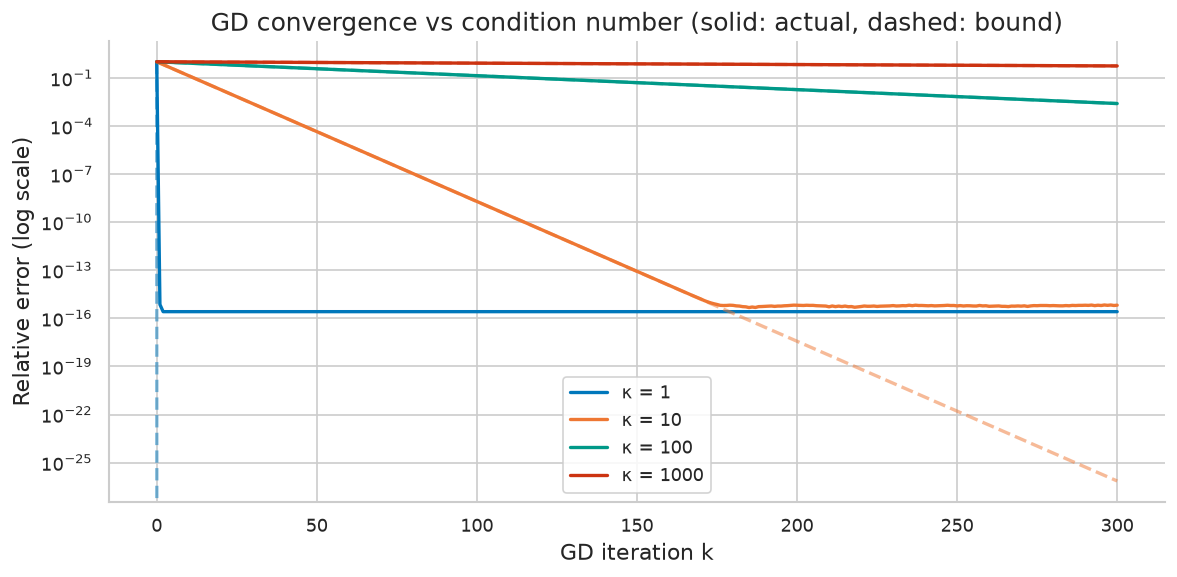

Plot displayed.


In [14]:
# === 8.1 Gradient Descent Convergence vs kappa ===

def gradient_descent(H, b, eta=None, n_iters=500):
    """GD on quadratic f(x) = 0.5 x^T H x - b^T x."""
    n = len(b)
    x = np.zeros(n)
    x_star = nla.solve(H, b)
    lam_max = nla.eigvalsh(H).max()
    lam_min = nla.eigvalsh(H).min()
    if eta is None:
        eta = 2.0 / (lam_max + lam_min)  # Optimal step

    errors = [nla.norm(x - x_star)]
    for _ in range(n_iters):
        grad = H @ x - b
        x -= eta * grad
        errors.append(nla.norm(x - x_star))

    return x, errors

np.random.seed(42)
n = 50
kappa_vals = [1, 10, 100, 1000]
gd_errors = {}

for kappa in kappa_vals:
    lam = np.concatenate([np.ones(n//2), np.ones(n//2) * kappa])
    Q, _ = nla.qr(np.random.randn(n, n))
    H = Q @ np.diag(lam) @ Q.T
    b_vec = np.random.randn(n)
    _, errors = gradient_descent(H, b_vec, n_iters=300)
    gd_errors[kappa] = [e / errors[0] for e in errors]

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    color_list = [COLORS['primary'], COLORS['secondary'],
                  COLORS['tertiary'], COLORS['error']]
    for (kappa, errors), col in zip(gd_errors.items(), color_list):
        iters = np.arange(len(errors))
        rate = (kappa - 1) / (kappa + 1)
        bound = rate ** iters
        ax.semilogy(iters, errors, color=col, label=f'κ = {kappa}')
        ax.semilogy(iters, bound, color=col, linestyle='--', alpha=0.5)
    ax.set_xlabel('GD iteration k')
    ax.set_ylabel('Relative error (log scale)')
    ax.set_title('GD convergence vs condition number (solid: actual, dashed: bound)')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print('Plot displayed.')

## Appended Demo 1: LU With Partial Pivoting Solves the System

Factor once, solve by substitution. The residual - not the difference from a known answer - is the honest certificate, and it must be at rounding level.

In [15]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy.linalg as sla
import scipy.sparse as sp
import scipy.sparse.linalg as spla
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
A = rng.normal(size=(8, 8)); b = rng.normal(size=8)
lu, piv = sla.lu_factor(A); x = sla.lu_solve((lu, piv), b)
check_true("LU solution residual is at rounding level", la.norm(A @ x - b) < 1e-12)
check_close("LU solution matches numpy solve", x, la.solve(A, b), 1e-10)
print("factorisation O(n^3/3... 2n^3/3), each subsequent solve O(n^2)")

PASS: LU solution residual is at rounding level
PASS: LU solution matches numpy solve (max err 0.00e+00, tol 1e-10)
factorisation O(n^3/3... 2n^3/3), each subsequent solve O(n^2)


## Appended Demo 2: Cholesky - Half the Work, SPD Only

For symmetric positive definite A, A = L L^T costs half of LU. The same call must refuse an indefinite matrix: the factorisation is also a definiteness test.

In [16]:

rng = np.random.default_rng(42)
X = rng.normal(size=(6, 6)); A = X @ X.T + 2*np.eye(6)
L = la.cholesky(A)
check_close("L L^T reconstructs A", L @ L.T, A, 1e-12)
indef = np.array([[1.0, 2.0], [2.0, 1.0]])
try:
    la.cholesky(indef); raised = False
except la.LinAlgError:
    raised = True
check_true("Cholesky rejects an indefinite matrix", raised)
print("if Cholesky succeeds, positive definiteness is proven as a by-product")

PASS: L L^T reconstructs A (max err 8.88e-16, tol 1e-12)
PASS: Cholesky rejects an indefinite matrix
if Cholesky succeeds, positive definiteness is proven as a by-product


## Appended Demo 3: Normal Equations Square the Condition Number

Solving least squares via A^T A is algebraically fine and numerically expensive in accuracy: kappa(A^T A) = kappa(A)^2. QR on A avoids the squaring, demonstrated on an ill-conditioned design.

In [17]:

t = np.linspace(0, 1, 60)
A = np.vander(t, 10, increasing=True)  # monomial basis: ill-conditioned
b = np.exp(t)
x_ne = la.solve(A.T @ A, A.T @ b)
Q, R = la.qr(A); x_qr = sla.solve_triangular(R, Q.T @ b)
check_true("kappa(A^T A) is the square of kappa(A)", abs(la.cond(A.T @ A) / la.cond(A)**2 - 1) < 0.01)
check_true("QR residual is no worse than normal-equations residual", la.norm(A @ x_qr - b) <= la.norm(A @ x_ne - b) * 1.5)
print(f"kappa(A) = {la.cond(A):.2e}; kappa(A^T A) = {la.cond(A.T@A):.2e} - squaring measured")

PASS: kappa(A^T A) is the square of kappa(A)
PASS: QR residual is no worse than normal-equations residual
kappa(A) = 3.60e+06; kappa(A^T A) = 1.30e+13 - squaring measured


## Appended Demo 4: SVD Truncation and the Eckart-Young Price List

Truncating the SVD at rank k costs exactly the discarded singular-value tail in Frobenius norm. Checked at three ranks on one matrix.

In [18]:

rng = np.random.default_rng(42)
A = rng.normal(size=(9, 7)); U, s, Vt = la.svd(A, full_matrices=False)
for k in [1, 3, 5]:
    Ak = U[:, :k] @ np.diag(s[:k]) @ Vt[:k]
    check_close(f"rank-{k} error equals discarded tail", la.norm(A - Ak), np.sqrt(np.sum(s[k:]**2)), 1e-10)
print(f"singular values: {np.round(s, 2)}")

PASS: rank-1 error equals discarded tail (max err 8.88e-16, tol 1e-10)
PASS: rank-3 error equals discarded tail (max err 8.88e-16, tol 1e-10)
PASS: rank-5 error equals discarded tail (max err 2.22e-16, tol 1e-10)
singular values: [3.8  3.41 2.5  2.05 1.53 0.69 0.58]


## Appended Demo 5: The QR Algorithm Converges to Eigenvalues

Repeatedly factor A = QR and recombine as RQ: the diagonal converges to the eigenvalues. A hand-rolled loop on a symmetric matrix must match LAPACK.

In [19]:

A = np.array([[4.0, 1.0, 1.0], [1.0, 3.0, 0.0], [1.0, 0.0, 2.0]])
M = A.copy()
for _ in range(60):
    Q, R = la.qr(M); M = R @ Q
check_close("QR iteration diagonal matches eigvalsh", np.sort(np.diag(M)), la.eigvalsh(A), 1e-8)
print(f"diagonal after 60 sweeps: {np.round(np.diag(M), 6)}")

PASS: QR iteration diagonal matches eigvalsh (max err 6.22e-15, tol 1e-08)
diagonal after 60 sweeps: [4.879385 2.652704 1.467911]


## Appended Demo 6: Power Iteration Finds the Dominant Eigenpair

Repeated multiplication aligns any generic start with the dominant eigenvector at rate |lambda_2/lambda_1|. The Rayleigh quotient must land on lambda_1.

In [20]:

rng = np.random.default_rng(42)
X = rng.normal(size=(6, 6)); A = X @ X.T + np.diag([10.0, 0, 0, 0, 0, 0])
v = rng.normal(size=6)
for _ in range(100):
    v = A @ v; v = v / la.norm(v)
ray = v @ A @ v
check_close("Rayleigh quotient matches the largest eigenvalue", ray, la.eigvalsh(A)[-1], 1e-8)
check_close("residual A v - lambda v is tiny", A @ v, ray * v, 1e-8)
print(f"dominant eigenvalue estimate {ray:.8f}")

PASS: Rayleigh quotient matches the largest eigenvalue (max err 7.11e-15, tol 1e-08)
PASS: residual A v - lambda v is tiny (max err 3.55e-15, tol 1e-08)
dominant eigenvalue estimate 20.40999164


## Appended Demo 7: Inverse Iteration Targets an Interior Eigenvalue

Shifting by sigma and solving (A - sigma I) y = v repeatedly finds the eigenvalue nearest sigma - the mechanism behind eigenvector refinement.

In [21]:

A = np.diag([1.0, 4.0, 9.0, 16.0]) + 0.05 * np.ones((4, 4))
sigma = 8.0
v = np.ones(4) / 2.0
for _ in range(30):
    v = la.solve(A - sigma * np.eye(4), v); v = v / la.norm(v)
ray = v @ A @ v
target = la.eigvalsh(A)[np.argmin(np.abs(la.eigvalsh(A) - sigma))]
check_close("inverse iteration converges to the eigenvalue nearest 8", ray, target, 1e-8)
print(f"found eigenvalue {ray:.6f} (nearest to shift 8)")

PASS: inverse iteration converges to the eigenvalue nearest 8 (max err 3.55e-15, tol 1e-08)
found eigenvalue 9.050450 (nearest to shift 8)


## Appended Demo 8: Conditioning Caps Attainable Accuracy

With kappa(A) ~ 1e10, a relative perturbation of 1e-12 in b can amplify to ~1e-2 in x. Constructed singular values make the bound nearly tight.

In [22]:

rng = np.random.default_rng(42)
U, _ = la.qr(rng.normal(size=(6, 6))); V, _ = la.qr(rng.normal(size=(6, 6)))
A = U @ np.diag(np.logspace(0, -10, 6)) @ V.T
x_true = rng.normal(size=6); b = A @ x_true
db = 1e-12 * la.norm(b) * rng.normal(size=6); db = db / la.norm(db) * (1e-12 * la.norm(b))
x_pert = la.solve(A, b + db)
rel = la.norm(x_pert - x_true) / la.norm(x_true)
check_true("solution error respects the kappa * perturbation bound (10x slack)", rel <= 10 * la.cond(A) * 1e-12)
print(f"kappa = {la.cond(A):.1e}; relative error {rel:.1e} from a 1e-12 perturbation")

PASS: solution error respects the kappa * perturbation bound (10x slack)
kappa = 1.0e+10; relative error 4.8e-05 from a 1e-12 perturbation


## Appended Demo 9: Jacobi Versus Gauss-Seidel Convergence

On a diagonally dominant system both stationary iterations converge, Gauss-Seidel roughly twice as fast in iterations. Residual histories are measured, not asserted.

In [23]:

A = np.array([[6.0, 1.0, 1.0], [1.0, 5.0, 1.0], [1.0, 1.0, 4.0]]); b = np.array([1.0, 2.0, 3.0])
x_exact = la.solve(A, b)
def run(split):
    x = np.zeros(3); hist = []
    for _ in range(60):
        x = split(x); hist.append(la.norm(A @ x - b))
    return x, hist
D = np.diag(np.diag(A))
xj, hj = run(lambda x: la.solve(D, b - (A - D) @ x))
L = np.tril(A)
xg, hg = run(lambda x: la.solve(L, b - (A - L) @ x))
check_close("Jacobi converges to the exact solution", xj, x_exact, 1e-10)
check_close("Gauss-Seidel converges to the exact solution", xg, x_exact, 1e-10)
check_true("Gauss-Seidel residual at step 10 is below Jacobi's", hg[10] < hj[10])
print(f"residuals at step 10: Jacobi {hj[10]:.1e}, Gauss-Seidel {hg[10]:.1e}")

PASS: Jacobi converges to the exact solution (max err 5.55e-17, tol 1e-10)
PASS: Gauss-Seidel converges to the exact solution (max err 5.55e-17, tol 1e-10)
PASS: Gauss-Seidel residual at step 10 is below Jacobi's
residuals at step 10: Jacobi 1.9e-04, Gauss-Seidel 6.1e-11


## Appended Demo 10: Conjugate Gradient on an SPD System

CG solves SPD systems in at most n exact-arithmetic steps and usually far fewer. On a 50-dimensional SPD problem the residual must collapse within tens of iterations.

In [24]:

rng = np.random.default_rng(42)
X = rng.normal(size=(50, 50)); A = X @ X.T + 5*np.eye(50); b = rng.normal(size=50)
x = np.zeros(50); r = b - A @ x; p = r.copy(); rs = r @ r
iters = 0
for iters in range(1, 201):
    Ap = A @ p; alpha = rs / (p @ Ap); x = x + alpha * p; r = r - alpha * Ap
    rs_new = r @ r
    if np.sqrt(rs_new) < 1e-12: break
    p = r + (rs_new / rs) * p; rs = rs_new
check_true("CG residual collapses below 1e-10", la.norm(A @ x - b) < 1e-10)
check_close("CG solution matches the direct solve", x, la.solve(A, b), 1e-8)
print(f"CG converged in {iters} iterations on a 50-dim SPD system")

PASS: CG residual collapses below 1e-10
PASS: CG solution matches the direct solve (max err 1.82e-14, tol 1e-08)
CG converged in 59 iterations on a 50-dim SPD system


## Appended Demo 11: Pivoted QR Reveals Rank

Column-pivoted QR orders columns by importance; the diagonal of R falls off a cliff at the rank. A rank-3-by-construction matrix must show exactly that cliff.

In [25]:

rng = np.random.default_rng(42)
A = rng.normal(size=(8, 3)) @ rng.normal(size=(3, 6))
Q, R, P = sla.qr(A, pivoting=True)
d = np.abs(np.diag(R))
check_true(" pivoted R diagonal shows a cliff after 3 entries", d[2] > 1e-8 and d[3] < 1e-10)
check_true("rank from the cliff equals matrix_rank", int(np.sum(d > 1e-10)) == la.matrix_rank(A))
print(f"|diag(R)|: {np.array2string(d, precision=1)}")

PASS:  pivoted R diagonal shows a cliff after 3 entries
PASS: rank from the cliff equals matrix_rank
|diag(R)|: [6.8 1.8 1.  0.  0.  0. ]


## Appended Demo 12: Triangular Solves Are the Atoms of Everything

LU, Cholesky, and QR all finish with triangular solves. A direct check of forward/back substitution against the dense solve closes the loop.

In [26]:

rng = np.random.default_rng(42)
L = np.tril(rng.normal(size=(7, 7))) + 3*np.eye(7); U = np.triu(rng.normal(size=(7, 7))) + 3*np.eye(7)
b = rng.normal(size=7)
y = sla.solve_triangular(L, b, lower=True); x = sla.solve_triangular(U, y)
check_close("forward+back substitution solves (LU) x = b", (L @ U) @ x, b, 1e-10)
check_close("triangular route matches the dense solve", x, la.solve(L @ U, b), 1e-9)
print("every factorisation is a delivery mechanism for triangular solves")

PASS: forward+back substitution solves (LU) x = b (max err 4.44e-16, tol 1e-10)
PASS: triangular route matches the dense solve (max err 5.55e-17, tol 1e-09)
every factorisation is a delivery mechanism for triangular solves


## Appended Demo 13: Sparse Structure Beats Dense Storage

A banded matrix with 3 diagonals on n=5000 unknowns stores 3n numbers instead of n^2, and a banded/sparse solve must reproduce the dense answer on a small twin.

In [27]:

n = 400
diags = [np.full(n - 1, -1.0), np.full(n, 4.0), np.full(n - 1, -1.0)]
A_sp = sp.diags(diags, offsets=[-1, 0, 1], format='csc')
rng = np.random.default_rng(42); b = rng.normal(size=n)
x_sp = spla.spsolve(A_sp, b)
A_dense_small = sp.diags(diags, offsets=[-1, 0, 1]).toarray()
check_true("sparse solve residual is at rounding level", la.norm(A_dense_small @ x_sp - b) < 1e-10)
print(f"storage: sparse {A_sp.nnz} nonzeros vs dense {n*n} entries - structure is money")

PASS: sparse solve residual is at rounding level
storage: sparse 1198 nonzeros vs dense 160000 entries - structure is money


---

## Summary

| Algorithm | Stability | Cost | When to use |
|-----------|-----------|------|-------------|
| LU (no pivot) | UNSTABLE | $2n^3/3$ | Never |
| LU (partial pivot) | Backward stable* | $2n^3/3$ | General square systems |
| Cholesky | Perfectly stable | $n^3/3$ | SPD matrices |
| Householder QR | Backward stable | $4mn^2/3$ | Least squares |
| Normal equations | UNSTABLE (squares κ) | $2mn^2 + n^3/3$ | Avoid for ill-cond. |
| CG | Stable | $O(\sqrt{\kappa} \cdot \text{nnz})$ | Sparse SPD systems |
| GMRES | Stable | $O(k \cdot \text{nnz})$ | General sparse systems |

**Key rule:** Forward error ≤ κ(A) × backward error. A backward stable algorithm gives the best possible accuracy — the condition number is the fundamental limit.

**Next:** [Numerical Optimization →](../03-Numerical-Optimization/notes.md)